# 5. AB 테스트 - Retriever 전략 비교

이 노트북은 5번 실험 전용 Qdrant collection을 새로 만들고, 같은 collection 안에 Dense Vector와 BM25 Sparse Vector를 함께 저장합니다.

비교 대상은 다음 세 가지입니다.

- A: Qdrant BM25 Sparse Search
- B: Qdrant Dense Vector Search
- C: Qdrant Hybrid Search


## 비교 원칙

검색기만 비교하려면 나머지 조건을 고정해야 합니다.

| 고정할 조건 | 이유 |
| --- | --- |
| 문서와 chunk 설정 | 문서 분할이 달라지면 검색기 차이를 분리하기 어려움 |
| 평가 질문과 기준 정답 | 같은 문제를 풀어야 비교 가능 |
| 답변 생성 모델과 프롬프트 | 생성 단계 차이를 최소화 |
| RAGAS 평가 지표와 평가 모델 | 점수 기준을 동일하게 유지 |

이 노트북에서는 5번 전용 Qdrant collection `retriever_strategy_comparison`을 새로 만들고, 같은 문서를 Dense Vector와 BM25 Sparse Vector로 함께 저장합니다. 이후 검색 모드만 `SPARSE`, `DENSE`, `HYBRID`로 바꿔 비교합니다.


In [1]:
from __future__ import annotations

import ast
import json
from pathlib import Path

import pandas as pd
from datasets import Dataset
from dotenv import load_dotenv
from IPython.display import display
from langchain_qdrant import FastEmbedSparse, QdrantVectorStore, RetrievalMode
from langchain_community.document_loaders import PDFPlumberLoader
from langchain_core.documents import Document
from langchain_core.output_parsers import StrOutputParser
from langchain_core.prompts import PromptTemplate
from langchain_openai import ChatOpenAI, OpenAIEmbeddings
from langchain_text_splitters import RecursiveCharacterTextSplitter
from qdrant_client import QdrantClient
from ragas import evaluate
from ragas.llms.base import LangchainLLMWrapper
from ragas.metrics import answer_relevancy, context_precision, context_recall, faithfulness

load_dotenv()

pd.set_option("display.max_colwidth", 120)

DATA_DIR = Path("./data")
PDF_PATH = DATA_DIR / "SPRI_AI_Brief_2023년12월호_F.pdf"
QUESTIONS_PATH = DATA_DIR / "evaluation_questions_for_ragas.csv"

METRICS = [
    "answer_relevancy",
    "faithfulness",
    "context_recall",
    "context_precision",
]


In [2]:
def parse_context_list(value):
    if isinstance(value, list):
        return value
    if pd.isna(value):
        return []
    try:
        parsed = ast.literal_eval(value)
    except (ValueError, SyntaxError):
        return [str(value)]
    return parsed if isinstance(parsed, list) else [str(parsed)]


questions = pd.read_csv(QUESTIONS_PATH)
questions["reference_contexts"] = questions["reference_contexts"].apply(parse_context_list)

# 수업 시간과 API 비용을 조절하려면 숫자를 줄입니다. 전체 평가를 하려면 None으로 바꿉니다.
MAX_EVAL_SAMPLES = 15
eval_questions = questions.head(MAX_EVAL_SAMPLES).copy() if MAX_EVAL_SAMPLES else questions.copy()

print(f"평가 질문 수: {len(eval_questions)}")
display(eval_questions[["user_input", "query_style", "query_category", "reference"]].head())


평가 질문 수: 15


,user_input,query_style,query_category,reference
0,바이든 대통령의 행정명령은 AI 개발과 사용에 대해 어떤 내용을 포함하고 있습니까?,WEB_SEARCH_LIKE,single_hop_specific,"바이든 대통령이 서명한 '안전하고 신뢰할 수 있는 AI 개발과 사용에 관한 행정명령'은 AI의 안전과 보안 기준 마련, 개인정보 보호 등 광범위한 행정 조치를 명시하고 있습니다."
1,주택 관련해서 AI가 어떻게 사용되나?,POOR_GRAMMAR,single_hop_specific,"형평성과 시민권 향상 차원에서 AI의 무책임한 사용으로 인한 차별과 편견을 방지하기 위한 조치를 확대하고, 주택 임대 시 AI 알고리즘 차별을 막기 위한 명확한 지침을 제공하고 있습니다."
2,"NAIRR의 목적은 무엇이며, 어떻게 미국 전역의 AI 연구를 촉진합니까?",PERFECT_GRAMMAR,single_hop_specific,"NAIRR(국가AI연구자원)는 미국 전역의 AI 연구를 촉진하기 위해 설계된 프로그램으로, 중소기업과 개발자에게 기술과 인프라를 지원하여 국가 차원에서 AI 연구 인프라를 확충하는 것을 목표로 합니다."
3,미국에서 AI와 관련된 규제를 다루는 Executive Order의 목적은 무엇인가요?,MISSPELLED,single_hop_specific,"Executive Order on the Safe, Secure, and Trustworthy Development and Use of Artificial Intelligence (E.O. 14110)은 분야..."
4,"IDC에 따르면 2027년 AI 소프트웨어 매출이 2,500억 달러를 넘을 것인데, AI SIS와 AI AD&D의 성장률은 어떻게 되나요?",NaN,multi_hop_specific,"IDC의 예측에 의하면 AI 소프트웨어 시장은 2027년 2,510억 달러에 이를 것으로 보이며, AI SIS는 현재 매출 규모는 작지만 5년간 연평균 성장률이 32.6%로 시장 전체를 웃돌 전망입니다. 또한..."


## 공통 문서 분할과 Qdrant Hybrid Collection 생성

BM25, Vector Search, Hybrid Search 모두 같은 문서와 같은 chunk를 사용해야 합니다.

여기서는 5번 실험 전용 Qdrant collection을 새로 만들고, 각 chunk를 Dense Vector와 BM25 Sparse Vector로 함께 저장합니다. 로컬 Qdrant는 `qdrant/` 폴더에서 `docker compose up -d`로 실행되어 있어야 합니다.


In [3]:
documents = PDFPlumberLoader(str(PDF_PATH)).load()

COMMON_CHUNK_SIZE = 500
COMMON_CHUNK_OVERLAP = 50
RETRIEVER_K = 4

splitter = RecursiveCharacterTextSplitter(
    chunk_size=COMMON_CHUNK_SIZE,
    chunk_overlap=COMMON_CHUNK_OVERLAP,
)
split_documents = splitter.split_documents(documents)

print(f"PDF 페이지 수: {len(documents)}")
print(f"분할 문서 수: {len(split_documents)}")


PDF 페이지 수: 23
분할 문서 수: 72


### hybrid_vectorstore

In [4]:
embeddings = OpenAIEmbeddings(model="text-embedding-3-small")
sparse_embeddings = FastEmbedSparse(model_name="Qdrant/bm25")

QDRANT_URL = "http://localhost:6333"
COLLECTION_NAME = "retriever_strategy_comparison"

qdrant_client = QdrantClient(url=QDRANT_URL)
if qdrant_client.collection_exists(collection_name=COLLECTION_NAME):
    qdrant_client.delete_collection(collection_name=COLLECTION_NAME)

hybrid_vectorstore = QdrantVectorStore.from_documents(
    documents=split_documents,
    embedding=embeddings,
    sparse_embedding=sparse_embeddings,
    retrieval_mode=RetrievalMode.HYBRID,
    url=QDRANT_URL,
    collection_name=COLLECTION_NAME,
)

### bm25_vectorstore

In [5]:
bm25_vectorstore = QdrantVectorStore.from_existing_collection(
    collection_name=COLLECTION_NAME,
    sparse_embedding=sparse_embeddings,
    retrieval_mode=RetrievalMode.SPARSE,
    url=QDRANT_URL,
)

### dense_vectorstore

In [6]:
dense_vectorstore = QdrantVectorStore.from_existing_collection(
    collection_name=COLLECTION_NAME,
    embedding=embeddings,
    retrieval_mode=RetrievalMode.DENSE,
    url=QDRANT_URL,
)

In [7]:
collection_count = qdrant_client.count(
    collection_name=COLLECTION_NAME,
    exact=True,
).count

print(f"생성한 Qdrant collection: {COLLECTION_NAME}")
print(f"Qdrant collection 문서 수: {collection_count}")

answer_llm = ChatOpenAI(model="gpt-4o-mini", temperature=0)

# answer_relevancy는 기본 strictness=3이므로 실제 3회 생성을 받도록 RAGAS LLM wrapper를 사용합니다.
judge_llm = LangchainLLMWrapper(
    ChatOpenAI(model="gpt-4o-mini", temperature=0),
    bypass_n=True,
)


생성한 Qdrant collection: retriever_strategy_comparison
Qdrant collection 문서 수: 72


### [Qdrant 접속](http://localhost:6333/dashboard#/collections)

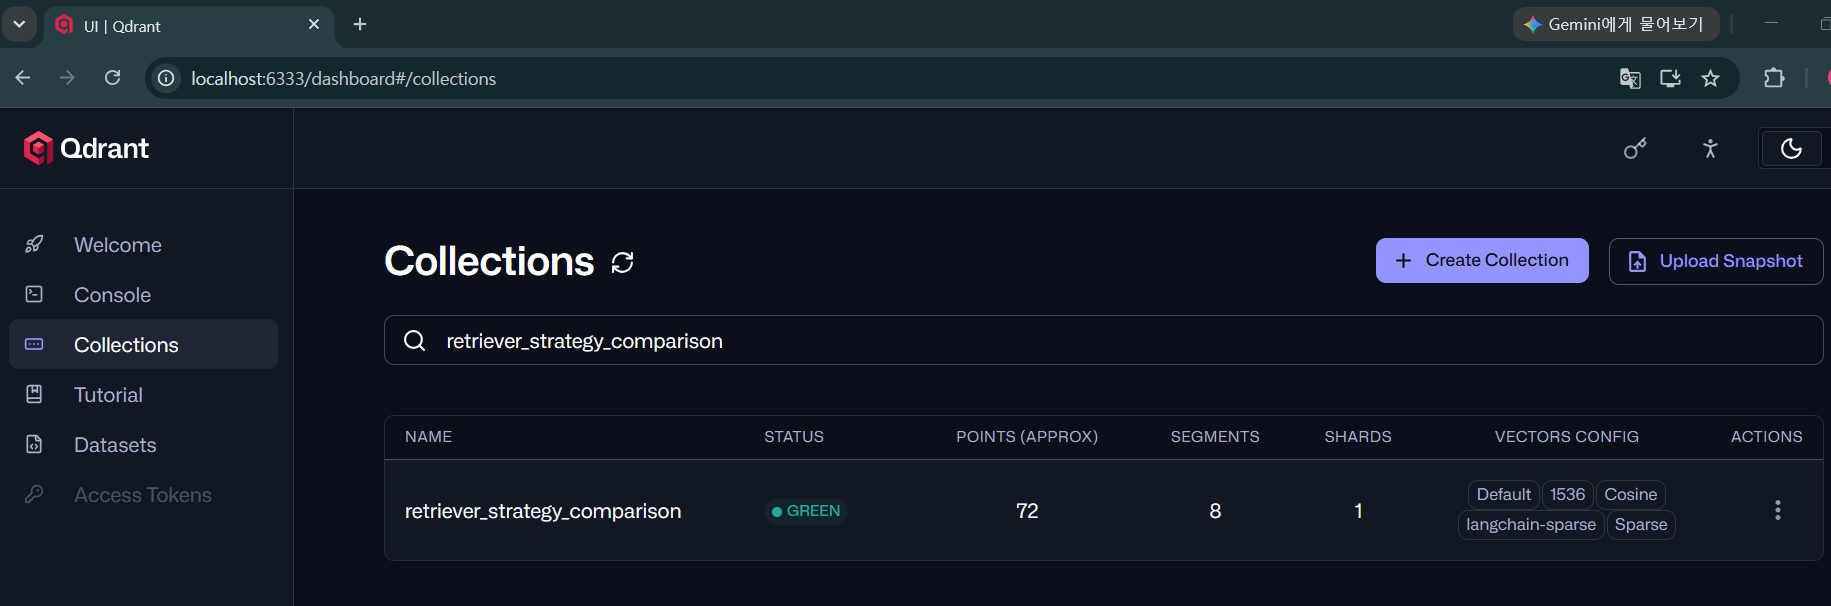

## Qdrant BM25 Sparse Search

Qdrant의 sparse vector 검색을 BM25 검색기로 사용합니다. 각 chunk는 `FastEmbedSparse(model_name="Qdrant/bm25")`로 sparse vector화되어 같은 Qdrant collection에 저장됩니다.


In [8]:
print(f"BM25 검색 모드: {bm25_vectorstore.retrieval_mode.value}")
print(f"Vector 검색 모드: {dense_vectorstore.retrieval_mode.value}")
print(f"Hybrid 검색 모드: {hybrid_vectorstore.retrieval_mode.value}")


BM25 검색 모드: sparse
Vector 검색 모드: dense
Hybrid 검색 모드: hybrid


## Vector Search와 Hybrid Search

Vector Search는 같은 Qdrant collection의 dense vector만 사용합니다.

Hybrid Search는 같은 collection 안의 dense vector와 BM25 sparse vector를 함께 조회하고, Qdrant/LangChain의 RRF(Reciprocal Rank Fusion) 방식으로 결과를 결합합니다.


In [9]:
def retrieve_bm25(query: str) -> list[Document]:
    return bm25_vectorstore.similarity_search(query, k=RETRIEVER_K)


def retrieve_vector(query: str) -> list[Document]:
    return dense_vectorstore.similarity_search(query, k=RETRIEVER_K)


def retrieve_hybrid(query: str) -> list[Document]:
    return hybrid_vectorstore.similarity_search(query, k=RETRIEVER_K)


RETRIEVER_CONFIGS = [
    {
        "config_name": "A. BM25 Sparse Search",
        "retriever_type": "Qdrant BM25 Sparse",
        "retrieve": retrieve_bm25,
        "answers_path": DATA_DIR / "rag_config_answers_bm25.csv",
        "scores_path": DATA_DIR / "rag_config_scores_bm25.csv",
    },
    {
        "config_name": "B. Dense Vector Search",
        "retriever_type": "Qdrant Dense Vector",
        "retrieve": retrieve_vector,
        "answers_path": DATA_DIR / "rag_config_answers_vector.csv",
        "scores_path": DATA_DIR / "rag_config_scores_vector.csv",
    },
    {
        "config_name": "C. Hybrid Search",
        "retriever_type": "Qdrant BM25 Sparse + Dense Vector",
        "retrieve": retrieve_hybrid,
        "answers_path": DATA_DIR / "rag_config_answers_hybrid.csv",
        "scores_path": DATA_DIR / "rag_config_scores_hybrid.csv",
    },
]


## 구성별 답변 생성

이 셀은 각 검색기로 실제 문서를 검색하고, 같은 LLM과 같은 프롬프트로 답변을 생성합니다.


In [10]:
RAG_PROMPT = PromptTemplate.from_template(
    """
당신은 문서 기반 질의응답 어시스턴트입니다.
반드시 아래 컨텍스트에서 확인할 수 있는 내용만 사용해 한국어로 답변하세요.
컨텍스트에 근거가 없으면 "제공된 문서에서는 확인할 수 없습니다."라고 답하세요.

# 컨텍스트
{context}

# 질문
{question}
"""
)

answer_chain = RAG_PROMPT | answer_llm | StrOutputParser()


def format_docs(docs: list[Document]) -> str:
    return "\n\n".join(doc.page_content for doc in docs)


def run_retriever_config(config: dict, question_df: pd.DataFrame) -> pd.DataFrame:
    rows = []
    retrieve = config["retrieve"]

    for row in question_df.itertuples(index=False):
        retrieved_docs = retrieve(row.user_input)
        contexts = [doc.page_content for doc in retrieved_docs]
        response = answer_chain.invoke(
            {
                "context": format_docs(retrieved_docs),
                "question": row.user_input,
            }
        )
        rows.append(
            {
                "config_name": config["config_name"],
                "retriever_type": config["retriever_type"],
                "user_input": row.user_input,
                "retrieved_contexts": contexts,
                "response": response,
                "reference": row.reference,
                "reference_contexts": row.reference_contexts,
            }
        )

    return pd.DataFrame(rows)


def save_answer_csv(answer_df: pd.DataFrame, path: Path) -> None:
    output = answer_df.copy()
    for column in ["retrieved_contexts", "reference_contexts"]:
        output[column] = output[column].apply(lambda value: json.dumps(value, ensure_ascii=False))
    output.to_csv(path, index=False, encoding="utf-8-sig")
    print(f"저장 완료: {path}")


In [11]:
answer_frames = []

for config in RETRIEVER_CONFIGS:
    print(f"답변 생성 중: {config['config_name']}")
    answer_df = run_retriever_config(config, eval_questions)
    save_answer_csv(answer_df, config["answers_path"])
    answer_frames.append(answer_df)

all_answers = pd.concat(answer_frames, ignore_index=True)
all_answers_path = DATA_DIR / "rag_configuration_answers.csv"
save_answer_csv(all_answers, all_answers_path)

display(all_answers[["config_name", "user_input", "response"]].head())


답변 생성 중: A. BM25 Sparse Search
저장 완료: data\rag_config_answers_bm25.csv
답변 생성 중: B. Dense Vector Search
저장 완료: data\rag_config_answers_vector.csv
답변 생성 중: C. Hybrid Search
저장 완료: data\rag_config_answers_hybrid.csv
저장 완료: data\rag_configuration_answers.csv


,config_name,user_input,response
0,A. BM25 Sparse Search,바이든 대통령의 행정명령은 AI 개발과 사용에 대해 어떤 내용을 포함하고 있습니까?,바이든 대통령의 행정명령은 AI 개발과 사용에 대해 다음과 같은 내용을 포함하고 있습니다: △AI의 안전과 보안 기준 마련 △개인정보보호 △형평성과 시민권 향상 △소비자 보호 △노동자 지원 △혁신과 경쟁 촉진...
1,A. BM25 Sparse Search,주택 관련해서 AI가 어떻게 사용되나?,제공된 문서에서는 확인할 수 없습니다.
2,A. BM25 Sparse Search,"NAIRR의 목적은 무엇이며, 어떻게 미국 전역의 AI 연구를 촉진합니까?","NAIRR(국가AI연구자원)의 목적은 국가 차원에서 AI 연구 인프라를 확충하여 더 많은 AI 연구자에게 인프라를 지원하는 것입니다. 이를 통해 미국 전역의 AI 연구를 촉진하고, 중소기업과 개발자에게 기술과..."
3,A. BM25 Sparse Search,미국에서 AI와 관련된 규제를 다루는 Executive Order의 목적은 무엇인가요?,제공된 문서에서는 확인할 수 없습니다.
4,A. BM25 Sparse Search,"IDC에 따르면 2027년 AI 소프트웨어 매출이 2,500억 달러를 넘을 것인데, AI SIS와 AI AD&D의 성장률은 어떻게 되나요?","AI SIS는 향후 5년간 연평균 성장률이 32.6%로 예상되며, AI AD&D는 가장 높은 38.7%의 연평균 성장률이 예상됩니다."


## RAGAS 평가

각 검색기 구성이 만든 답변을 같은 RAGAS 지표로 평가합니다.


In [12]:
def diagnose_rag_failure(row: pd.Series, threshold: float = 0.70) -> str:
    retrieval_low = min(row["context_recall"], row["context_precision"]) < threshold
    generation_low = min(row["answer_relevancy"], row["faithfulness"]) < threshold

    if retrieval_low and generation_low:
        return "검색과 생성 모두 점검"
    if retrieval_low:
        return "검색 단계 우선 점검"
    if generation_low:
        return "생성 단계 우선 점검"
    return "큰 문제 없음"


def evaluate_answers(answer_df: pd.DataFrame, config: dict) -> pd.DataFrame:
    dataset = Dataset.from_pandas(
        answer_df[["user_input", "retrieved_contexts", "response", "reference", "reference_contexts"]],
        preserve_index=False,
    )
    result = evaluate(
        dataset=dataset,
        metrics=[answer_relevancy, faithfulness, context_recall, context_precision],
        llm=judge_llm,
    )
    score_df = result.to_pandas()
    score_df["config_name"] = config["config_name"]
    score_df["retriever_type"] = config["retriever_type"]
    score_df[METRICS] = score_df[METRICS].apply(pd.to_numeric, errors="coerce")
    score_df["min_score"] = score_df[METRICS].min(axis=1)
    score_df["diagnosis"] = score_df.apply(diagnose_rag_failure, axis=1)
    score_df.to_csv(config["scores_path"], index=False, encoding="utf-8-sig")
    print(f"저장 완료: {config['scores_path']}")
    return score_df


In [13]:
score_frames = []

for config, answer_df in zip(RETRIEVER_CONFIGS, answer_frames):
    print(f"RAGAS 평가 중: {config['config_name']}")
    score_frames.append(evaluate_answers(answer_df, config))

all_scores = pd.concat(score_frames, ignore_index=True)
scores_path = DATA_DIR / "rag_configuration_scores.csv"
all_scores.to_csv(scores_path, index=False, encoding="utf-8-sig")
print(f"저장 완료: {scores_path}")

display(all_scores[["config_name", "user_input", *METRICS, "min_score", "diagnosis"]].head())


RAGAS 평가 중: A. BM25 Sparse Search


Evaluating:   0%|          | 0/60 [00:00<?, ?it/s]

저장 완료: data\rag_config_scores_bm25.csv
RAGAS 평가 중: B. Dense Vector Search


Evaluating:   0%|          | 0/60 [00:00<?, ?it/s]

저장 완료: data\rag_config_scores_vector.csv
RAGAS 평가 중: C. Hybrid Search


Evaluating:   0%|          | 0/60 [00:00<?, ?it/s]

저장 완료: data\rag_config_scores_hybrid.csv
저장 완료: data\rag_configuration_scores.csv


,config_name,user_input,answer_relevancy,faithfulness,context_recall,context_precision,min_score,diagnosis
0,A. BM25 Sparse Search,바이든 대통령의 행정명령은 AI 개발과 사용에 대해 어떤 내용을 포함하고 있습니까?,0.859297,1.0,1.0,1.000000,0.859297,큰 문제 없음
1,A. BM25 Sparse Search,주택 관련해서 AI가 어떻게 사용되나?,0.000000,1.0,1.0,0.250000,0.000000,검색과 생성 모두 점검
2,A. BM25 Sparse Search,"NAIRR의 목적은 무엇이며, 어떻게 미국 전역의 AI 연구를 촉진합니까?",0.835779,1.0,1.0,1.000000,0.835779,큰 문제 없음
3,A. BM25 Sparse Search,미국에서 AI와 관련된 규제를 다루는 Executive Order의 목적은 무엇인가요?,0.000000,0.0,1.0,0.250000,0.000000,검색과 생성 모두 점검
4,A. BM25 Sparse Search,"IDC에 따르면 2027년 AI 소프트웨어 매출이 2,500억 달러를 넘을 것인데, AI SIS와 AI AD&D의 성장률은 어떻게 되나요?",0.849385,1.0,1.0,0.805556,0.805556,큰 문제 없음


## A/B 테스트 평가 

아래 코드는 실제로 측정한 RAGAS 평균 점수와 낮은 점수 샘플 수를 구성별로 비교합니다.
운영 비용과 지연 시간은 서비스 의사결정에서 추가로 확인할 항목이며, 이 실습 코드에서는 정량 측정하지 않습니다.


### 평균점수(weighted_score)
> 평균 점수는 전체적으로 어떤 Retriever가 더 잘하는지 보기 위해 구합니다.

```txt
A. BM25 평균 점수: 0.82
B. Dense 평균 점수: 0.86
C. Hybrid 평균 점수: 0.89
```

이렇게 나오면 “전체적으로는 Hybrid가 가장 안정적으로 좋은 답변을 만들었다”고 판단할 수 있습니다.

In [14]:
# 평가 지표별 중요도를 정해 질문 단위의 종합 점수를 계산합니다.
WEIGHTS = pd.Series(
    {
        "answer_relevancy": 0.25,
        "faithfulness": 0.30,
        "context_recall": 0.25,
        "context_precision": 0.20,
    }
)

all_scores["weighted_score"] = all_scores[METRICS].mul(WEIGHTS).sum(axis=1)

### 낮은 점수 샘플 수 
> 평균 점수만 보면 문제가 생깁니다.

```txt
A 구성 점수: 0.9, 0.9, 0.9, 0.9, 0.4 -> 평균: 0.80
B 구성 점수: 0.8, 0.8, 0.8, 0.8, 0.8 -> 평균: 0.80
```
- 둘 다 평균은 같습니다. 하지만 실제 서비스에서는 A가 더 위험합니다.
- 왜냐하면 특정 질문에서 0.4처럼 크게 실패한 샘플이 있기 때문입니다.

그래서 낮은 점수 샘플 수를 구합니다.


In [15]:
# 평균이 높아도 특정 지표가 크게 낮은 샘플은 별도로 점검합니다.
all_scores["is_low_score"] = all_scores["min_score"] < 0.70

### 평가 

In [16]:
# 구성별 평균 점수와 낮은 점수 샘플 수를 하나의 비교표로 집계합니다.
summary = (
    all_scores
    .groupby(["config_name", "retriever_type"])
    .agg(
        answer_relevancy=("answer_relevancy", "mean"),
        faithfulness=("faithfulness", "mean"),
        context_recall=("context_recall", "mean"),
        context_precision=("context_precision", "mean"),
        min_score=("min_score", "mean"),
        weighted_score=("weighted_score", "mean"),
        low_score_count=("is_low_score", "sum"),
        sample_count=("user_input", "count"),
    )
    .reset_index()
)

# 가중 평균 점수가 높은 순서로 순위를 매기고,
# 같은 순위에서는 낮은 점수 샘플이 적은 구성을 먼저 확인합니다.
summary["rank"] = summary["weighted_score"].rank(ascending=False, method="dense").astype(int)
summary = summary.sort_values(["rank", "low_score_count", "config_name"])

display(summary.round(4))


,config_name,retriever_type,answer_relevancy,faithfulness,context_recall,context_precision,min_score,weighted_score,low_score_count,sample_count,rank
2,C. Hybrid Search,Qdrant BM25 Sparse + Dense Vector,0.5707,0.8111,0.9167,0.8444,0.5480,0.7841,6,15,1
1,B. Dense Vector Search,Qdrant Dense Vector,0.5738,0.7754,0.9333,0.8556,0.5563,0.7805,6,15,2
0,A. BM25 Sparse Search,Qdrant BM25 Sparse,0.4530,0.7244,0.9111,0.8037,0.4312,0.7191,7,15,3


#### 질문의 유형(query_category)별 평가 

| query_category | 의미 | 예시 질문 |
|---|---|---|
| `single_hop_specific` | 문서 안의 특정 정보 하나만 찾으면 답할 수 있는 질문 | “RAGAS에서 faithfulness는 무엇을 평가하나요?” |
| `multi_hop_specific` | 여러 문장이나 여러 문서 조각의 구체적인 정보를 연결해야 답할 수 있는 질문 | “평가 데이터셋을 만들고 나서 RAG 답변 데이터셋을 생성하는 순서는 어떻게 되나요?” |
| `multi_hop_abstract` | 여러 정보를 종합해서 추상적인 개념, 비교, 판단을 해야 하는 질문 | “RAG 평가에서 context recall과 context precision을 함께 봐야 하는 이유는 무엇인가요?” |
| `out_of_domain` | 제공된 강의자료 범위 밖의 질문 | “주식 자동매매 시스템에서 손절 전략은 어떻게 설계하나요?” |
| `conditional_multi_hop` | 조건이 붙어 있고, 그 조건에 맞는 여러 정보를 연결해야 답할 수 있는 질문 | “답변은 맞지만 검색 문맥이 부족한 경우라면 어떤 RAGAS 지표를 먼저 확인해야 하나요?” |
| `conditional` | 특정 조건에 따라 답이 달라지는 질문 | “OpenAI API 키가 없으면 이 노트북을 실행할 수 있나요?” |
| `multi_hop_manual` | 자동 평가만으로 판단하기 어렵고, 사람이 여러 근거를 직접 확인해야 하는 복합 질문 | “이 Retriever 구성을 실제 서비스에 적용해도 되는지 판단하려면 어떤 결과를 추가로 봐야 하나요?” |

In [17]:
category_summary = (
    all_scores
    .merge(eval_questions[["user_input", "query_category"]], on="user_input", how="left")
    .groupby(["config_name", "query_category"])
    .agg(
        weighted_score=("weighted_score", "mean"),
        min_score=("min_score", "mean"),
        sample_count=("user_input", "count"),
    )
    .reset_index()
    .sort_values(["query_category", "weighted_score"], ascending=[True, False])
)

display(category_summary.round(4))


,config_name,query_category,weighted_score,min_score,sample_count
14,C. Hybrid Search,conditional,0.9649,0.8598,1
7,B. Dense Vector Search,conditional,0.9632,0.8528,1
0,A. BM25 Sparse Search,conditional,0.9555,0.8222,1
15,C. Hybrid Search,conditional_multi_hop,0.7765,0.6667,1
8,B. Dense Vector Search,conditional_multi_hop,0.5810,0.0000,1
1,A. BM25 Sparse Search,conditional_multi_hop,0.5667,0.0000,1
16,C. Hybrid Search,multi_hop_abstract,0.7718,0.5368,3
9,B. Dense Vector Search,multi_hop_abstract,0.7685,0.5371,3
2,A. BM25 Sparse Search,multi_hop_abstract,0.7319,0.5148,3
17,C. Hybrid Search,multi_hop_manual,0.9629,0.8516,1


#### 낮은 점수를 받은 실제 질문들을 꺼내서 확인

In [20]:
low_cases = (
    all_scores
    .loc[all_scores["min_score"] < 0.70, ["config_name", "user_input", *METRICS, "min_score", "diagnosis", "response", "reference"]]
    .sort_values(["config_name", "min_score"])
)

print(f"낮은 점수 샘플 수: {len(low_cases)}")
display(low_cases.head())


낮은 점수 샘플 수: 19


,config_name,user_input,answer_relevancy,faithfulness,context_recall,context_precision,min_score,diagnosis,response,reference
1,A. BM25 Sparse Search,주택 관련해서 AI가 어떻게 사용되나?,0.0,1.000000,1.000000,0.25,0.0,검색과 생성 모두 점검,제공된 문서에서는 확인할 수 없습니다.,"형평성과 시민권 향상 차원에서 AI의 무책임한 사용으로 인한 차별과 편견을 방지하기 위한 조치를 확대하고, 주택 임대 시 AI 알고리즘 차별을 막기 위한 명확한 지침을 제공하고 있습니다."
3,A. BM25 Sparse Search,미국에서 AI와 관련된 규제를 다루는 Executive Order의 목적은 무엇인가요?,0.0,0.000000,1.000000,0.25,0.0,검색과 생성 모두 점검,제공된 문서에서는 확인할 수 없습니다.,"Executive Order on the Safe, Secure, and Trustworthy Development and Use of Artificial Intelligence (E.O. 14110)은 분야..."
5,A. BM25 Sparse Search,2023년 11월 8일 삼성 AI 포럼에서 공개된 삼성 가우스와 관련하여 구글의 앤스로픽 투자 소식은 어떤 연관이 있나요?,0.0,0.000000,0.666667,1.00,0.0,검색과 생성 모두 점검,제공된 문서에서는 확인할 수 없습니다.,"2023년 11월 8일 삼성 AI 포럼에서 삼성전자가 자체 개발한 생성 AI 모델 ‘삼성 가우스’를 공개했습니다. 같은 날 블룸버그 보도에 따르면, 구글은 앤스로픽과 4년간 30억 달러 규모의 클라우드 서비스..."
7,A. BM25 Sparse Search,영국 AI 안전 연구소의 설립과 블레츨리 선언이 AI 시스템의 효과적 거버넌스와 투명성 향상에 어떻게 기여할 것으로 예상되나요?,0.0,0.000000,0.666667,1.00,0.0,검색과 생성 모두 점검,제공된 문서에서는 확인할 수 없습니다.,영국 AI 안전 연구소는 첨단 AI 시스템 평가와 AI 안전 연구를 통해 AI 시스템의 효과적 거버넌스를 위한 도구 개발 및 안전한 AI 시스템 개발을 위한 새로운 접근 방식을 연구할 계획입니다. 블레츨리 선...
10,A. BM25 Sparse Search,"AI 행정명령과 G7 국제 행동강령을 비교해, 둘 다 공통으로 요구하는 위험 관리 조치 2가지와 G7 행동강령에 더 구체적으로 나온 조치 1가지를 구분해서 답하세요.",0.0,0.666667,0.666667,1.00,0.0,검색과 생성 모두 점검,"제공된 문서에서는 AI 행정명령에 대한 구체적인 내용이 포함되어 있지 않으므로, G7 국제 행동강령에서 요구하는 위험 관리 조치만을 바탕으로 답변하겠습니다.\n\nG7 국제 행동강령에서 공통으로 요구하는 위험...",두 문서 모두 첨단 AI 시스템의 위험을 평가하고 완화하는 조치와 투명성/책임성 강화를 요구합니다. 미국 AI 행정명령은 강력한 AI 시스템 개발 기업이 안전 테스트 결과와 주요 정보를 미국 정부와 공유하도록...


### 결과 저장 

In [19]:
summary_path = DATA_DIR / "rag_configuration_summary.csv"
summary.to_csv(summary_path, index=False, encoding="utf-8-sig")
print(f"저장 완료: {summary_path}")

best_config = summary.iloc[0]
print(f"선택 후보: {best_config['config_name']}")
print(f"가중 평균 점수: {best_config['weighted_score']:.4f}")
print(f"낮은 점수 샘플 수: {int(best_config['low_score_count'])}")


저장 완료: data\rag_configuration_summary.csv
선택 후보: C. Hybrid Search
가중 평균 점수: 0.7841
낮은 점수 샘플 수: 6
